,delivery_bucket,orders,avg_review,pct_bad_reviews
0,1. On time,88163,4.29,9.2
1,2. 1-3 days late,2636,3.77,19.1
2,3. 4-7 days late,1773,2.32,61.3
3,4. 8+ days late,3252,1.73,78.3


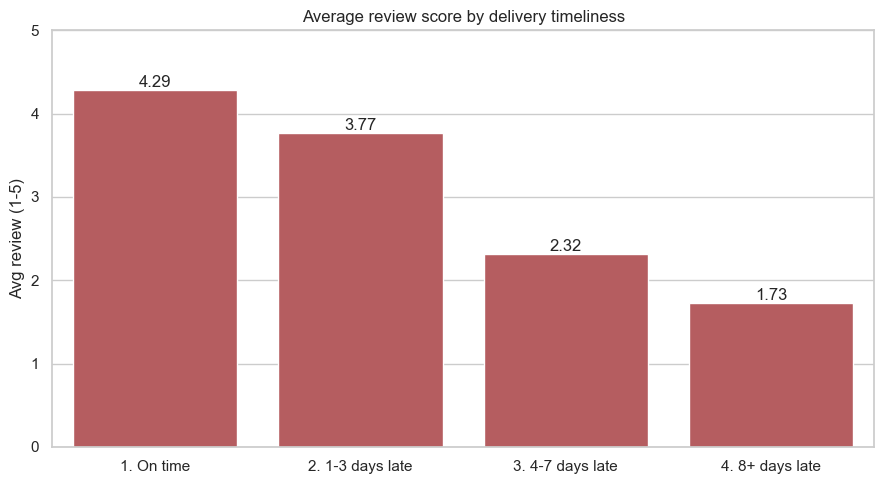

In [7]:
delivery = run_sql("04_delivery_vs_reviews.sql", "delivery_vs_reviews.csv")
display(delivery)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=delivery, x="delivery_bucket", y="avg_review", color="#C44E52")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Average review score by delivery timeliness")
plt.xlabel(""); plt.ylabel("Avg review (1-5)"); plt.ylim(0, 5)
plt.tight_layout()
plt.savefig(ROOT / "outputs" / "delivery_vs_reviews.png", dpi=150)
plt.show()

,delivery_bucket,customers,repeat_rate_pct
0,1. On time,51256,4.04
1,2. 1-3 days late,1318,3.57
2,3. 4-7 days late,954,3.25
3,4. 8+ days late,1995,2.96


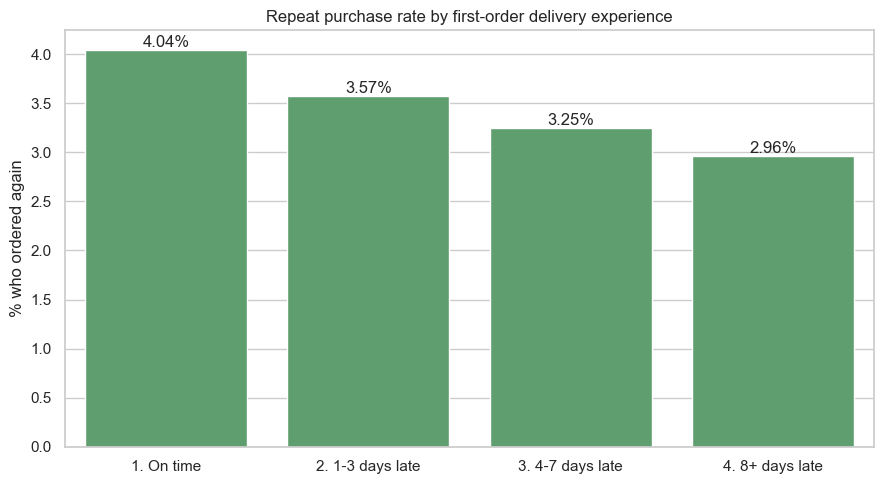

In [8]:
repeat = run_sql("05_first_order_delivery_repeat.sql", "first_order_delivery_repeat.csv")
display(repeat)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=repeat, x="delivery_bucket", y="repeat_rate_pct", color="#55A868")
ax.bar_label(ax.containers[0], fmt="%.2f%%")
plt.title("Repeat purchase rate by first-order delivery experience")
plt.xlabel(""); plt.ylabel("% who ordered again")
plt.tight_layout()
plt.savefig(ROOT / "outputs" / "repeat_by_delivery.png", dpi=150)
plt.show()

,segment,customers,total_revenue,avg_spend
0,New High-Value,14428,4360657.0,302.24
1,At Risk High-Value,13757,4235679.0,307.89
2,Mid-tier One-timers,18070,2736347.0,151.43
3,Lapsed,22594,1640519.0,72.61
4,New / Recent,21707,1584902.0,73.01
5,Champions,2238,809137.0,361.54
6,Loyal,563,55220.0,98.08


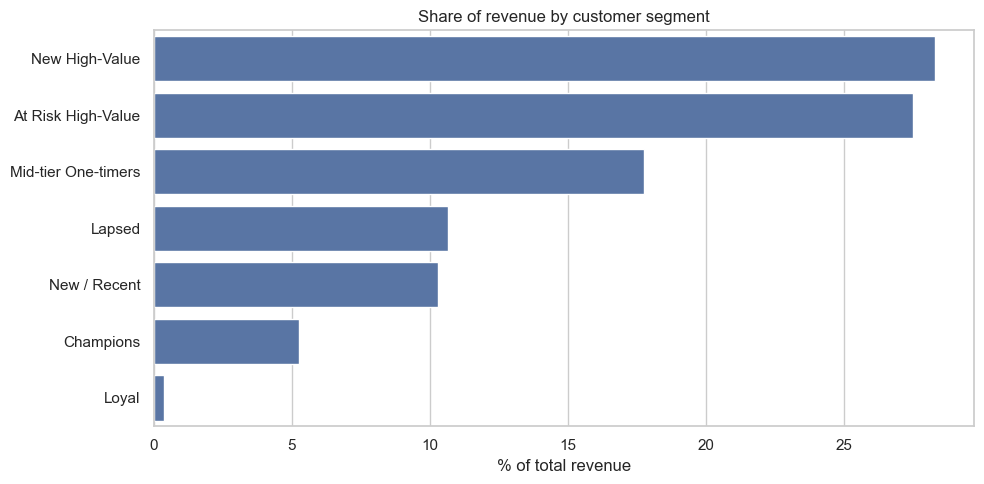

In [6]:
rfm = run_sql("03_rfm_segmentation.sql", "rfm_segments.csv")
display(rfm)

rfm["revenue_share_pct"] = 100 * rfm["total_revenue"] / rfm["total_revenue"].sum()
plt.figure(figsize=(10, 5))
sns.barplot(data=rfm, x="revenue_share_pct", y="segment", color="#4C72B0")
plt.title("Share of revenue by customer segment")
plt.xlabel("% of total revenue"); plt.ylabel("")
plt.tight_layout()
plt.savefig(ROOT / "outputs" / "rfm_revenue_share.png", dpi=150)
plt.show()

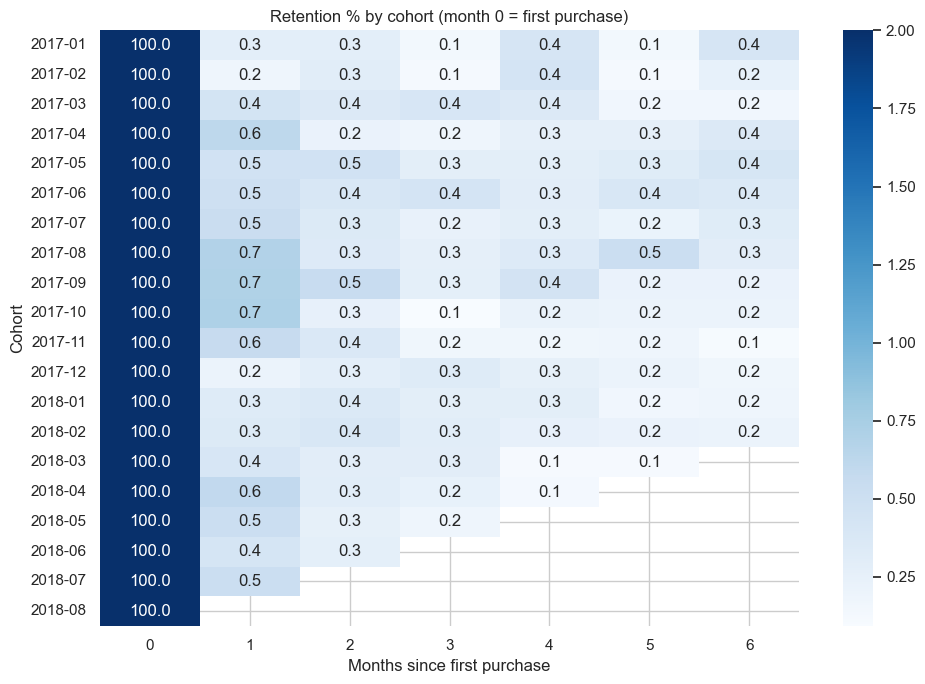

In [5]:
cohort = run_sql("02_cohort_retention.sql", "cohort_raw.csv")
pivot = cohort.pivot(index="cohort_month", columns="months_since_first",
                     values="active_customers")
retention = (pivot.div(pivot[0], axis=0) * 100).loc["2017-01":, 0:6]

plt.figure(figsize=(10, 7))
sns.heatmap(retention, annot=True, fmt=".1f", cmap="Blues", vmax=2)
plt.title("Retention % by cohort (month 0 = first purchase)")
plt.ylabel("Cohort"); plt.xlabel("Months since first purchase")
plt.tight_layout()
plt.savefig(ROOT / "outputs" / "cohort_heatmap.png", dpi=150)
plt.show()

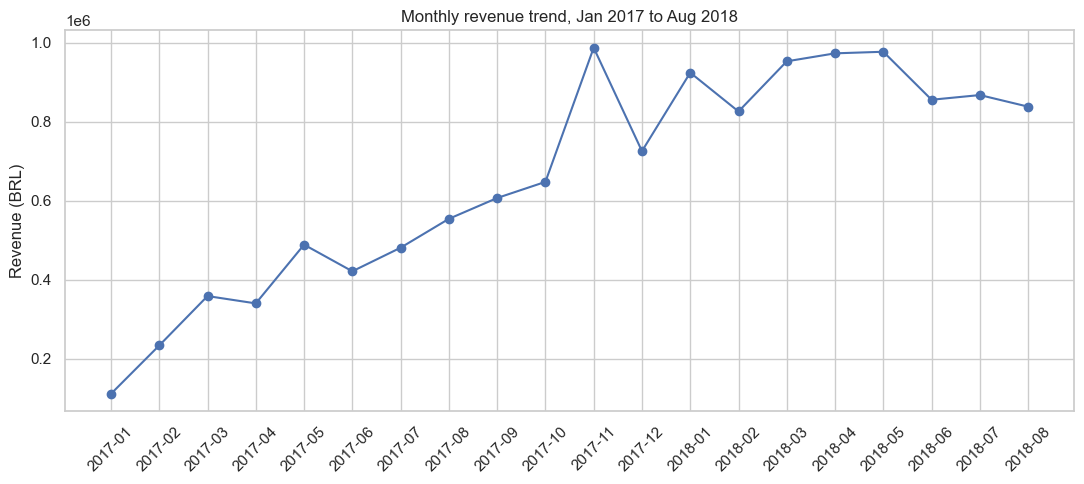

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly["month"], monthly["revenue"], marker="o")
ax.set_title("Monthly revenue trend, Jan 2017 to Aug 2018")
ax.set_ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(ROOT / "outputs" / "revenue_trend.png", dpi=150)
plt.show()

In [3]:
monthly = run_sql("01_monthly_revenue.sql", "monthly_revenue.csv")
monthly

,month,orders,revenue,aov,mom_growth_pct
0,2017-01,750,111798.36,149.06,NaN
1,2017-02,1653,234223.40,141.70,109.5
2,2017-03,2546,359198.85,141.08,53.4
3,2017-04,2303,340669.68,147.92,-5.2
4,2017-05,3546,489338.25,138.00,43.6
5,2017-06,3135,421923.37,134.58,-13.8
6,2017-07,3872,481604.52,124.38,14.1
7,2017-08,4193,554699.70,132.29,15.2
8,2017-09,4150,607399.67,146.36,9.5
9,2017-10,4478,648247.65,144.76,6.7


In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ROOT = Path("..")
conn = sqlite3.connect(ROOT / "olist.db")
(ROOT / "outputs").mkdir(exist_ok=True)

def run_sql(filename, save_as=None):
    df = pd.read_sql((ROOT / "sql" / filename).read_text(), conn)
    if save_as:
        df.to_csv(ROOT / "outputs" / save_as, index=False)
    return df

sns.set_theme(style="whitegrid")